# $V_3$ closure test with HERA $xF_3^{\gamma Z}$ kinematics

This notebook follows the pseudo-data workflow of `T3_demo.ipynb`. The fitted PDF is

$$V_3(x,Q_0)=(u-\bar u)-(d-\bar d),$$

represented through $xV_3$ on the evolved FK grid. By default, PDF combinations other than $V_3$ are held fixed to their NNPDF reference prediction, and pseudo-data are drawn from

$$D_i^{\rm pseudo}\sim\mathcal N\!\left(b_i+v(c_{\rm true};Q_i^2)\,[W(xV_3^{\rm ref})]_i,\Sigma\right), \qquad b_i=\text{offset}_i.$$

The real HERA central values remain available as `D_real`. The `data_mode` and background choices are isolated in Section 2 so they can be changed later.

## Outline
1. Load and inspect the HERA inputs
2. Configure the background, EFT model, and pseudo-data
3. Inspect the reference $V_3$
4. Construct the B-spline design matrix
5. Separate, joint, and one-step fits
6. Compare the fitted PDF and predictions with pseudo-data
7. Simulation Study

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import lhapdf

from scipy.integrate import quad
from scipy.linalg import cho_factor, cho_solve
from scipy.stats import norm

from T3_utils import (
    bspline_basis,
    klin, kquad, v_c, v_prime_c,
    build_K_matrix, build_K_prime_matrix,
    fit_beta_c, mle_beta, mle_c, one_step_c,
    one_step_confidence_interval, bootstrap_confidence_interval,
    plot_by_Q2,
)

---
## 1. Load the HERA data and FK matrices

`D_real` contains the measured central values. `W` is the physical $V_3$ matrix, including the conversion from the Yadism `F3_total` normalization to measured $xF_3^{\gamma Z}$. It multiplies $xV_3$ on `grid`.

Set `data_replication_factor` to 2 or 3 to study an enlarged pseudo-dataset. Each copy repeats the original kinematics and theory rows, retains the original covariance within that copy, and is statistically independent of the other copies. Consequently, every replicated point has the same marginal variance as its original point.

Or more directly, scale down the covariance matrix.

In [2]:
archive = np.load("Dataset/data_HERA_F3_aZ.npz")

# Effective sample-size study: use 1 for the original data, or 2/3 to
# create independent copies at the same kinematic points.
data_replication_factor = 1
if isinstance(data_replication_factor, bool) or not isinstance(data_replication_factor, (int, np.integer)):
    raise TypeError("data_replication_factor must be a positive integer")
if data_replication_factor < 1:
    raise ValueError("data_replication_factor must be at least 1")

Q0 = float(archive["Q0"])
grid = archive["grid"]
W_base = archive["W"]
W_all_base = archive["W_all"]
channel_pids = archive["channel_pids"]
Sigma_base = archive["Sigma"]
xQ2_base = archive["kinematics"]
D_real_base = archive["data"]
errors_base = archive["errors"]
stat_errors_base = archive["stat_errors"]
sys_errors_base = archive["sys_errors"]
prediction_reference_base = archive["prediction"]
prediction_v3_reference_base = archive["prediction_v3"]
prediction_rest_reference_base = archive["prediction_rest"]
xv3_reference = archive["xv3_grid"]
v3_reference = archive["v3_grid"]

# Stack complete independent copies. np.kron gives a block-diagonal
# covariance diag(Sigma_base, ..., Sigma_base), rather than correlating
# measurements belonging to different copies.
R = data_replication_factor
W = np.tile(W_base, (R, 1))
W_all = np.tile(W_all_base, (R, 1, 1))
xQ2 = np.tile(xQ2_base, (R, 1))
Sigma = np.kron(np.eye(R), Sigma_base)
D_real = np.concatenate([D_real_base] * R, axis=0)
errors = np.concatenate([errors_base] * R, axis=0)
stat_errors = np.concatenate([stat_errors_base] * R, axis=0)
sys_errors = np.concatenate([sys_errors_base] * R, axis=0)
prediction_reference = np.concatenate([prediction_reference_base] * R, axis=0)
prediction_v3_reference = np.concatenate([prediction_v3_reference_base] * R, axis=0)
prediction_rest_reference = np.concatenate([prediction_rest_reference_base] * R, axis=0)

print(f"Replication factor = {R}; N_data = {len(D_real)} ({len(D_real_base)} x {R})")
print(f"N_grid = {len(grid)}, Q0 = {Q0:g} GeV")
print(f"W: {W.shape}; W_all: {W_all.shape}")
print(f"x range: [{xQ2[:, 0].min():.4g}, {xQ2[:, 0].max():.4g}]")
print(f"Q² range: [{xQ2[:, 1].min():.0f}, {xQ2[:, 1].max():.0f}] GeV²")
print("Evolution-basis channels:", channel_pids.tolist())
assert np.allclose(W @ xv3_reference, prediction_v3_reference)
assert np.allclose(np.diag(Sigma), np.tile(np.diag(Sigma_base), R))

Replication factor = 1; N_data = 67 (67 x 1)
N_grid = 30, Q0 = 1.65 GeV
W: (67, 30); W_all: (67, 9, 30)
x range: [0.013, 0.65]
Q² range: [1000, 30000] GeV²
Evolution-basis channels: [21, 103, 108, 115, 100, 203, 208, 215, 200]


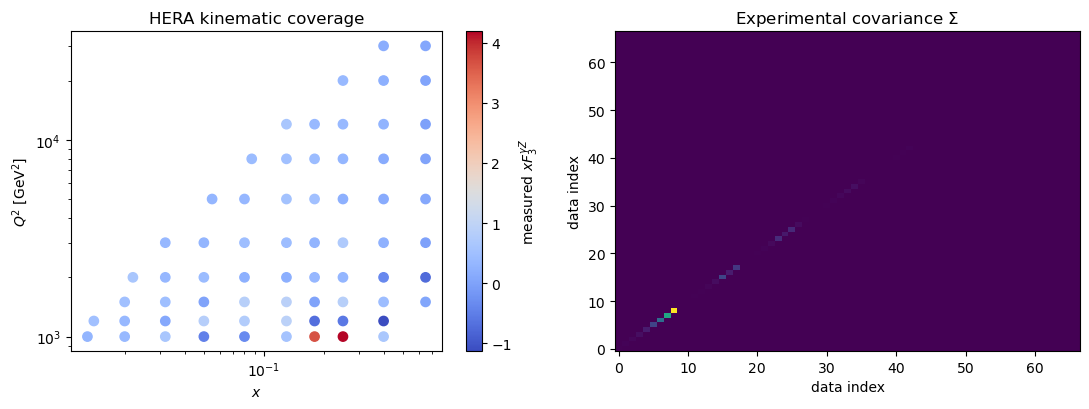

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

sc = axes[0].scatter(xQ2[:, 0], xQ2[:, 1], c=D_real, cmap="coolwarm", s=45)
axes[0].set(xscale="log", yscale="log", xlabel="$x$", ylabel="$Q^2$ [GeV$^2$]", title="HERA kinematic coverage")
fig.colorbar(sc, ax=axes[0], label=r"measured $xF_3^{\gamma Z}$")

axes[1].imshow(Sigma, origin="lower", aspect="auto", cmap="viridis")
axes[1].set(xlabel="data index", ylabel="data index", title="Experimental covariance $\Sigma$")
plt.tight_layout()
plt.show()

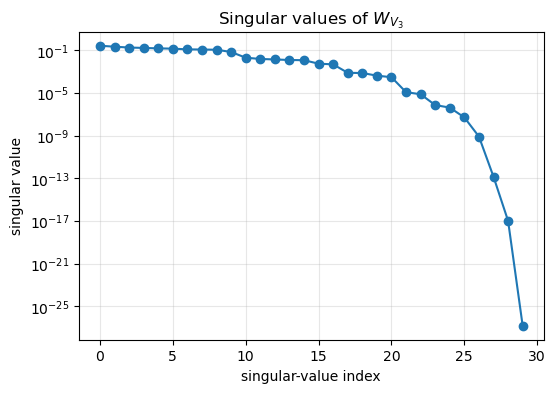

In [5]:
singular_values = np.linalg.svd(W, compute_uv=False)
plt.figure(figsize=(6, 4))
plt.semilogy(singular_values, "o-")
plt.xlabel("singular-value index")
plt.ylabel("singular value")
plt.title(r"Singular values of $W_{V_3}$")
plt.grid(alpha=0.3)
plt.show()

---
## 2. Background and EFT configuration

`background_mode` controls the non-$V_3$ contribution:

- `"fixed_nnpdf"` (default): use the saved NNPDF contribution from all other channels;
- `"none"`: treat the measurement as if it were purely $V_3$;
- `"custom"`: supply a length-67 array in `custom_background`.

After pseudo-data generation, all fitting routines operate on `D_fit = D - background`, which is algebraically equivalent to including the fixed additive background in the likelihood.

In [6]:
background_mode = "fixed_nnpdf"  # "fixed_nnpdf", "none", or "custom"
custom_background = None

if background_mode == "fixed_nnpdf":
    background = prediction_rest_reference.copy()
elif background_mode == "none":
    background = np.zeros_like(D_real)
elif background_mode == "custom":
    if custom_background is None:
        raise ValueError("Set custom_background to an array with the same shape as D_real")
    background = np.asarray(custom_background, dtype=float)
    if background.shape != D_real.shape:
        raise ValueError(f"custom_background has shape {background.shape}; expected {D_real.shape}")
else:
    raise ValueError(f"Unknown background_mode: {background_mode!r}")

print("background mode:", background_mode)

background mode: fixed_nnpdf


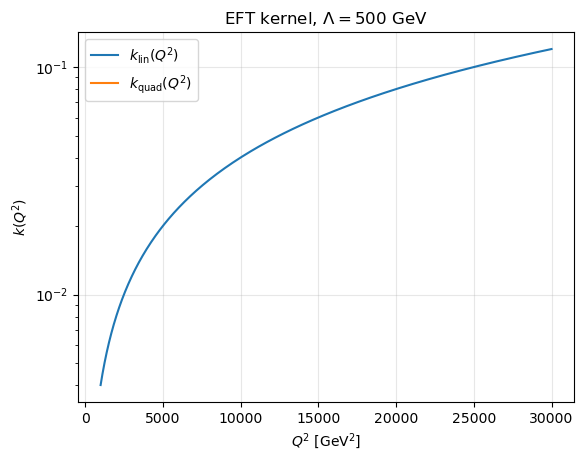

In [ ]:
# EFT factor v(c,Q²) = 1 + Q^2 c / Lambda^2 + Q^4 c / Lambda^4.
Lambda = 500.0
_klin = lambda z: klin(z, Lambda=Lambda)
#_kquad = lambda z: kquad(z, Lambda=Lambda)
_kquad = lambda z, **kwargs: np.zeros_like(np.asarray(z, dtype=float))
_v_c = lambda c, xQ2: v_c(c, xQ2, klin=_klin, kquad=_kquad)

assert np.allclose(_v_c(0.0, xQ2), 1.0)

q2_plot = np.geomspace(xQ2[:, 1].min(), xQ2[:, 1].max(), 300)
plt.plot(q2_plot, _klin(q2_plot), label=r"$k_{\rm lin}(Q^2)$")
plt.plot(q2_plot, _kquad(q2_plot), label=r"$k_{\rm quad}(Q^2)$")
plt.xlabel("$Q^2$ [GeV$^2$]")
plt.ylabel(r"$k(Q^2)$")
plt.yscale("log")
plt.title(fr"EFT kernel, $\Lambda={Lambda:g}$ GeV")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Generate pseudo-data

With `data_mode = "pseudo"`, the analysis vector is one reproducible Gaussian draw around the reference $V_3$ prediction at `c_true`. Set `data_mode = "real"` to use the measured HERA central values instead.

The replication option is intended for pseudo-data: the block-diagonal covariance generates independent observations in each copy. In `real` mode, replication merely repeats the same observed central values and should not be interpreted as genuinely new data. Under regular $1/\sqrt{N}$ behavior, multiplying the sample size by `R` should reduce standard errors by approximately $1/\sqrt{R}$.

In [71]:
data_mode = "pseudo"  # "pseudo" or "real"
c_true = 5
pseudo_seed = None

mu_v3_true = _v_c(c_true, xQ2) * prediction_v3_reference
mu_pseudo = background + mu_v3_true
rng = np.random.default_rng(pseudo_seed)
D_pseudo = rng.multivariate_normal(mean=mu_pseudo, cov=Sigma)

if data_mode == "pseudo":
    D = D_pseudo
elif data_mode == "real":
    D = D_real.copy()
else:
    raise ValueError("data_mode must be 'pseudo' or 'real'")

D_fit = D - background
print(f"data mode: {data_mode}")
print(f"c_true = {c_true:g}; pseudo-data seed = {pseudo_seed}")

data mode: pseudo
c_true = 5; pseudo-data seed = None


---
## 3. Reference $V_3$ and predictions

The reference curve defines the pseudo-data generating mean and the default fixed background. The fit itself uses only `D`, `Sigma`, `W`, and the selected background.

LHAPDF 6.5.5 loading /Users/richardzhs/miniforge3/envs/hep/share/LHAPDF/NNPDF40_nnlo_as_01180/NNPDF40_nnlo_as_01180_0000.dat
NNPDF40_nnlo_as_01180 PDF set, member #0, version 1; LHAPDF ID = 331100


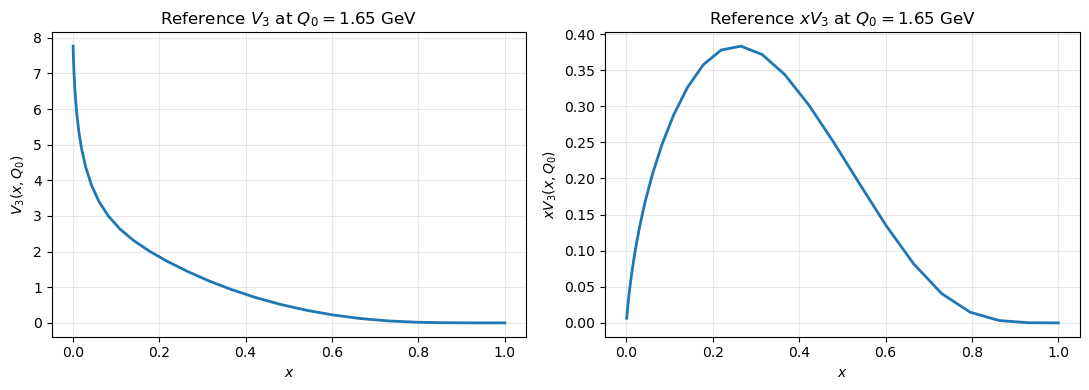

c=0 reference chi2/N = 125.368/67 = 1.871
Generating-mean chi2/N = 88.145/67 = 1.316


In [72]:
pdfset = str(archive["pdfset"])
pdf_member = int(archive["pdf_member"])
pdf = lhapdf.mkPDF(pdfset, pdf_member)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(grid, v3_reference, lw=2)
axes[0].set(xlabel="$x$", ylabel="$V_3(x,Q_0)$", title=fr"Reference $V_3$ at $Q_0={Q0:g}$ GeV")
axes[1].plot(grid, xv3_reference, lw=2)
axes[1].set(xlabel="$x$", ylabel="$xV_3(x,Q_0)$", title=fr"Reference $xV_3$ at $Q_0={Q0:g}$ GeV")
for ax in axes:
    #ax.set_xscale("log")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

sigma_factor = cho_factor(Sigma)
chi2_reference = (D - prediction_reference) @ cho_solve(sigma_factor, D - prediction_reference)
chi2_generation = (D - mu_pseudo) @ cho_solve(sigma_factor, D - mu_pseudo)
print(f"c=0 reference chi2/N = {chi2_reference:.3f}/{len(D)} = {chi2_reference/len(D):.3f}")
if data_mode == "pseudo":
    print(f"Generating-mean chi2/N = {chi2_generation:.3f}/{len(D)} = {chi2_generation/len(D):.3f}")

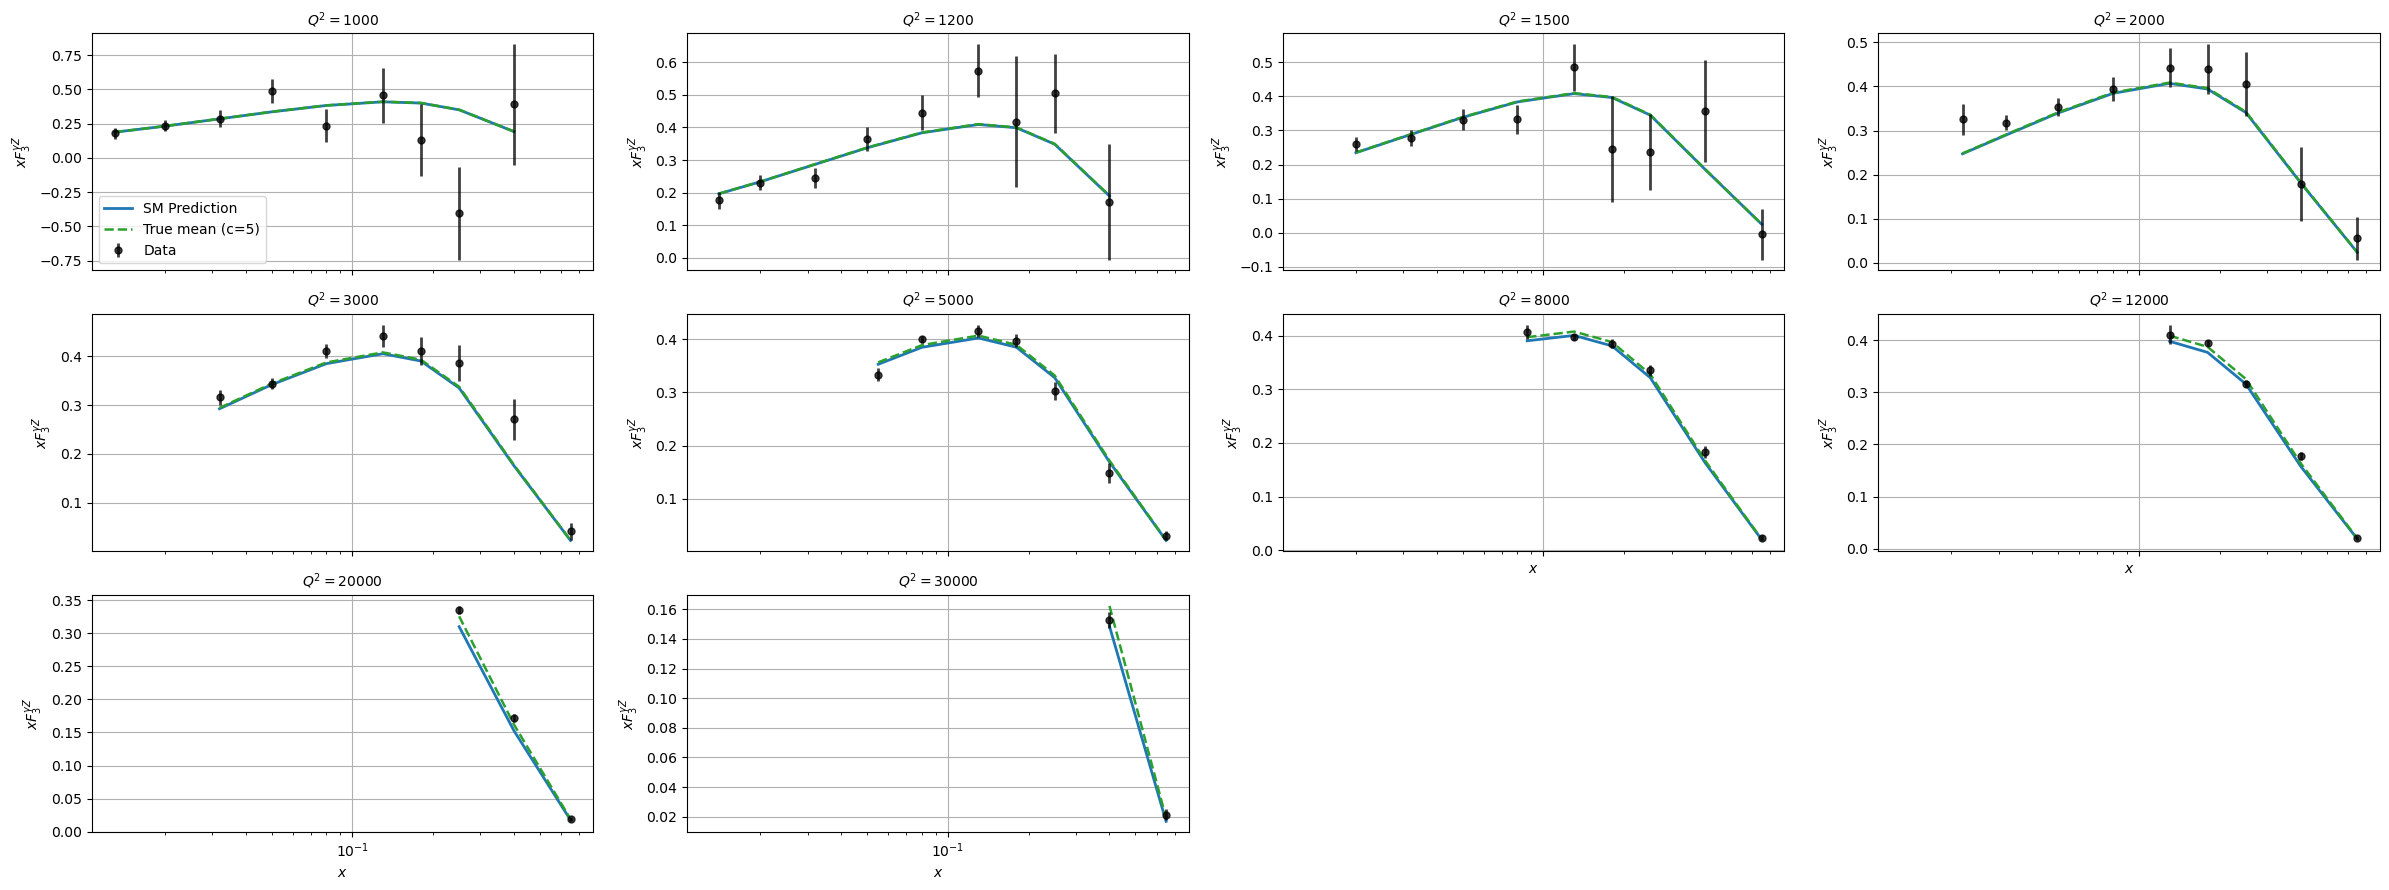

In [73]:
one_sigma_alpha = 2.0 * (1.0 - norm.cdf(1.0))

fig = plot_by_Q2(
    {"SM Prediction": prediction_reference, f"True mean (c={c_true:g})": mu_pseudo, "Data": D},
    xQ2=xQ2, ncols=4, x_log_scale=True, alpha=one_sigma_alpha,
    series_styles={
        "SM Prediction": dict(color="C0", linewidth=2),
        f"True mean (c={c_true:g})": dict(color="C2", linewidth=1.8, linestyle="--"),
        "Data": dict(kind="scatter", cov=Sigma, color="black", s=25, alpha=0.75),
    },
    y_label=r"$xF_3^{\gamma Z}$",
)

---
## 4. B-spline representation of $xV_3$

The primary parametrization is

$$xV_3(x)=\sum_{k=1}^M\beta_k B_k(x), \qquad A_{ik}=\sum_j W_{ij}B_k(x_j).$$

The optional valence sum rule is

$$\int_0^1 V_3(x)\,dx=\int_0^1\frac{xV_3(x)}{x}\,dx=1.$$

Since the FK grid begins at a small positive $x$, the numerical constraint is applied over the grid range. Set `enforce_sum_rule=False` to remove it.

In [74]:
degree = 3
M = 8
parametrize = "xV3"  # alternatively: "V3"
enforce_sum_rule = True
nonnegative_pdf = True
pin_endpoints = True

x_min, x_max = float(grid.min()), float(grid.max())
B = bspline_basis(degree, M, x_min, x_max)
B_grid = np.vstack([Bk(grid) for Bk in B])

if parametrize == "xV3":
    # W multiplies xV3 directly.
    A = W @ B_grid.T
    w_sum_rule = np.array([quad(lambda z, Bk=Bk: Bk(z) / z, x_min, x_max)[0] for Bk in B])
elif parametrize == "V3":
    # xV3 = x * V3.
    A = W @ (grid[:, None] * B_grid.T)
    w_sum_rule = np.array([Bk.integrate(x_min, x_max) for Bk in B])
else:
    raise ValueError("parametrize must be 'xV3' or 'V3'")

w_norm = w_sum_rule if enforce_sum_rule else None
print(f"Parametrization: {parametrize}; A shape: {A.shape}")
print("Enforce V3 sum rule:", enforce_sum_rule)
print("Condition number of A:", np.linalg.cond(A))

Parametrization: xV3; A shape: (67, 8)
Enforce V3 sum rule: True
Condition number of A: 3126.143409726017


---
## 5. Fits to the pseudo-data

### 5a. Separate fit

First fit the spline coefficients at $c=0$, then fit $c$ with the PDF fixed. The likelihood uses `D_fit`; the full prediction is recovered by adding `background`.

In [75]:
c0 = 0.0
loss_scale = 1e2  # improves optimizer scaling for c_true=20 pseudo-data

beta_hat_sep, beta_history = mle_beta(
    D=D_fit, A=A, c=c0, v=_v_c, xQ2=xQ2, Sigma=Sigma,
    w_norm=w_norm, nonneg_beta=nonnegative_pdf, pin_endpoints=pin_endpoints,
    beta_opt="SLSQP", return_history=True, loss_scale=loss_scale,
)

c_hat_sep = mle_c(
    D=D_fit, A=A, v=_v_c, beta=beta_hat_sep, xQ2=xQ2, Sigma=Sigma,
    c_opt="L-BFGS-B", c_range=(-20, 20),
)

print(f"True c = {c_true:.6g}")
print(f"Separate-fit c = {c_hat_sep:.6g} (error {c_hat_sep - c_true:+.6g})")
if w_norm is not None:
    print(f"V3 sum rule = {w_norm @ beta_hat_sep:.8f}")

True c = 5
Separate-fit c = 0.737248 (error -4.26275)
V3 sum rule = 1.00000000


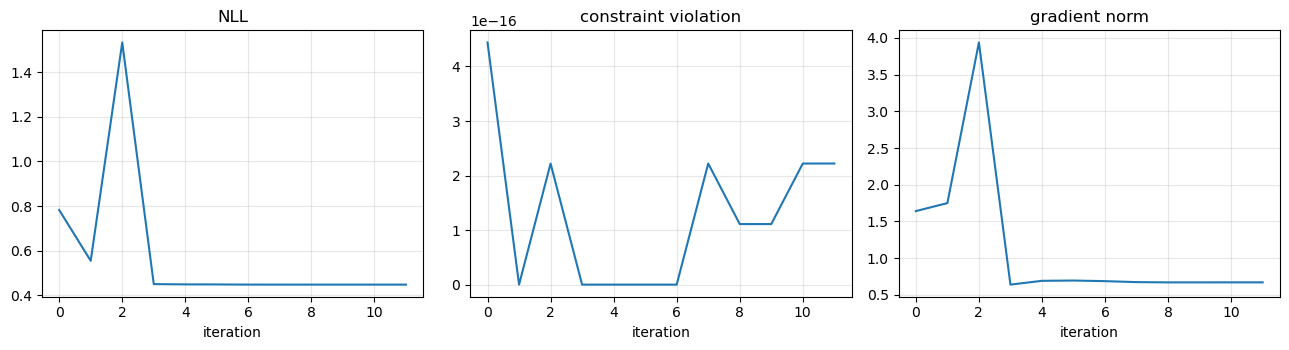

In [76]:
history_sep = pd.DataFrame(beta_history)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, column, title in zip(axes, ["loss", "constr_viol", "grad_norm"], ["NLL", "constraint violation", "gradient norm"]):
    ax.plot(history_sep[column])
    ax.set(title=title, xlabel="iteration")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5b. Joint fit

Fit the spline coefficients and $c$ simultaneously.

In [77]:
joint_result, joint_history = fit_beta_c(
    D=D_fit, A=A, v=_v_c, v_prime=_v_prime_c, c0=c0,
    w_norm=w_norm, xQ2=xQ2, Sigma=Sigma,
    nonneg_beta=nonnegative_pdf, pin_endpoints=pin_endpoints,
    return_history=True, opt_method="SLSQP", loss_scale=loss_scale,
)

beta_hat_joint = joint_result.beta_hat
c_hat_joint = joint_result.c_hat
print("Optimizer success:", joint_result.success, "-", joint_result.message)
print(f"True c = {c_true:.6g}")
print(f"Joint-fit c = {c_hat_joint:.6g} (error {c_hat_joint - c_true:+.6g})")
if w_norm is not None:
    print(f"V3 sum rule = {w_norm @ beta_hat_joint:.8f}")

Optimizer success: True - Optimization terminated successfully
True c = 5
Joint-fit c = 4.04963 (error -0.950374)
V3 sum rule = 1.00000000


Choose which plug-in estimate to carry into the one-step calculation and final plots.

In [55]:
fit_method = "joint"  # "separate" or "joint"

if fit_method == "separate":
    beta_hat, c_hat = beta_hat_sep, c_hat_sep
elif fit_method == "joint":
    beta_hat, c_hat = beta_hat_joint, c_hat_joint
else:
    raise ValueError("fit_method must be 'separate' or 'joint'")

### 5c. One-step estimator

In [78]:
K = build_K_matrix(c_hat, A, xQ2=xQ2, klin=_klin, kquad=_kquad)
K_prime = build_K_prime_matrix(c_hat, A, xQ2=xQ2, klin=_klin, kquad=_kquad)

c_one_step, one_step_info = one_step_c(
    D_fit, K, K_prime, beta_hat, c_hat, w_norm=w_norm,
    s2_diag=np.diag(Sigma), pin_endpoints=pin_endpoints,
)
ci_os_lower, ci_os_upper, se_os = one_step_confidence_interval(one_step_info)

print(f"True c                    = {c_true:.6g}")
print(f"Plug-in c ({fit_method}) = {c_hat:.6g} (error {c_hat - c_true:+.6g})")
print(f"One-step c                 = {c_one_step:.6g} (error {c_one_step - c_true:+.6g})")
print(f"EIF correction         = {one_step_info['eif']:.6g}")
print(f"Analytical 95% CI      = [{ci_os_lower:.6g}, {ci_os_upper:.6g}]")

True c                    = 5
Plug-in c (joint) = 4.41964 (error -0.580364)
One-step c                 = 2.1199 (error -2.8801)
EIF correction         = -2.29973
Analytical 95% CI      = [-2.81403, 7.05384]


### Optional parametric-bootstrap interval

This is disabled by default because it repeatedly refits the model. Set `run_bootstrap=True` when desired. It resamples around the fitted model to quantify uncertainty for this closure test.

In [79]:
run_bootstrap = False

if run_bootstrap:
    ci_boot_lower, ci_boot_upper, bootstrap_samples = bootstrap_confidence_interval(
        A=A, xQ2=xQ2, Sigma=Sigma, w_norm=w_norm, c0=c0,
        c_hat=c_hat, beta_hat=beta_hat, n_boot=500, alpha=0.05,
        estimator="mle", klin=_klin, kquad=_kquad,
        nonneg_beta=nonnegative_pdf, pin_endpoints=pin_endpoints,
        opt=fit_method, c_opt="L-BFGS-B", verbose=True,
    )
    print(f"Bootstrap 95% CI = [{ci_boot_lower:.6g}, {ci_boot_upper:.6g}]")

---
## 6. Results

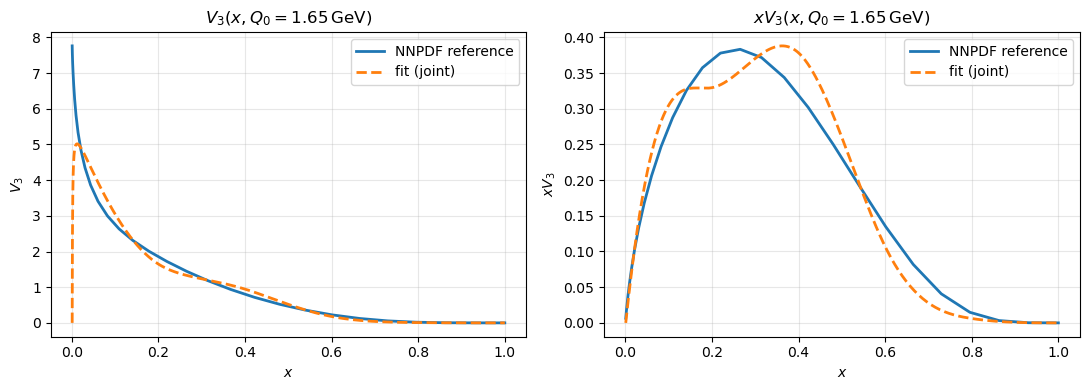

In [80]:
plot_x = np.geomspace(x_min, x_max, 1000)
basis_plot = np.vstack([Bk(plot_x) for Bk in B])
fit_basis = beta_hat @ basis_plot

if parametrize == "xV3":
    xv3_hat_plot = fit_basis
    v3_hat_plot = fit_basis / plot_x
else:
    v3_hat_plot = fit_basis
    xv3_hat_plot = plot_x * fit_basis

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(grid, v3_reference, lw=2, label="NNPDF reference")
axes[0].plot(plot_x, v3_hat_plot, lw=2, ls="--", label=fr"fit ({fit_method})")
axes[0].set(xlabel="$x$", ylabel="$V_3$", title=fr"$V_3(x,Q_0={Q0:g}\,\mathrm{{GeV}})$")
axes[1].plot(grid, xv3_reference, lw=2, label="NNPDF reference")
axes[1].plot(plot_x, xv3_hat_plot, lw=2, ls="--", label=fr"fit ({fit_method})")
axes[1].set(xlabel="$x$", ylabel="$xV_3$", title=fr"$xV_3(x,Q_0={Q0:g}\,\mathrm{{GeV}})$")
for ax in axes:
    #ax.set_xscale("log")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Fit chi2/N = 93.013/67 = 1.388
True mean chi2/N = 88.145/67 = 1.316


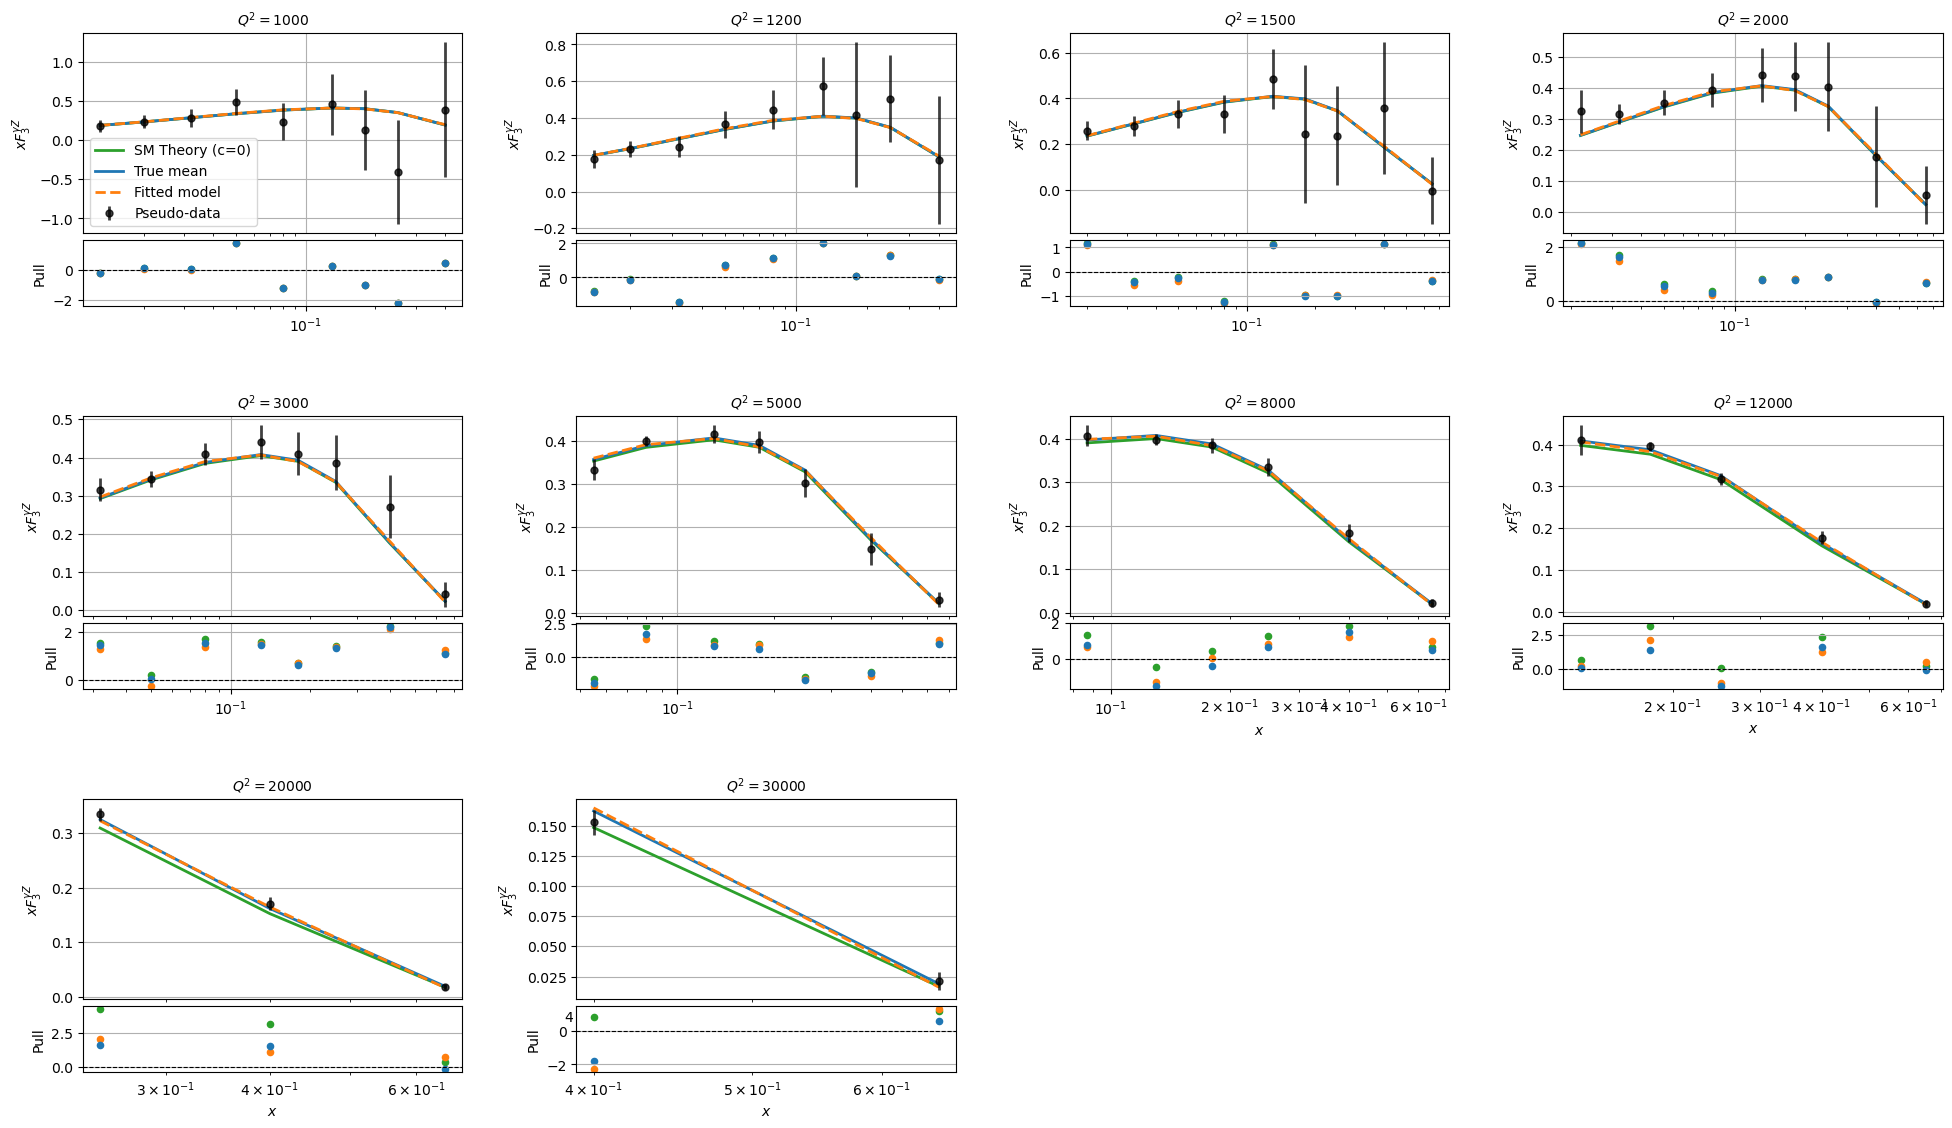

In [81]:
v3_fit_prediction = _v_c(c_hat, xQ2) * (A @ beta_hat)
full_fit_prediction = background + v3_fit_prediction
residual = D - full_fit_prediction
chi2_fit = residual @ cho_solve(cho_factor(Sigma), residual)

print(f"Fit chi2/N = {chi2_fit:.3f}/{len(D)} = {chi2_fit/len(D):.3f}")
print(f"True mean chi2/N = {chi2_generation:.3f}/{len(D)} = {chi2_generation/len(D):.3f}")

fig = plot_by_Q2(
    {"SM Theory (c=0)": prediction_reference, "True mean": mu_pseudo, "Fitted model": full_fit_prediction, "Pseudo-data": D},
    xQ2=xQ2, ncols=4, x_log_scale=True, alpha=0.05,
    series_styles={
        "SM Theory (c=0)": dict(linestyle="-",  linewidth=2, color="C2"),
        "True mean": dict(color="C0", linewidth=2),
        "Fitted model": dict(color="C1", linewidth=2, linestyle="--"),
        "Pseudo-data": dict(kind="scatter", cov=Sigma, color="black", s=25, alpha=0.75),
    },
    pull=[
        {"data": "Pseudo-data", "ref": "SM Theory (c=0)", "color": "C2"},
        {"data": "Pseudo-data", "ref": "Fitted model", "color": "C1"},
        {"data": "Pseudo-data", "ref": "True mean", "color": "C0"},
    ],
    y_label=r"$xF_3^{\gamma Z}$",
)

In [82]:
summary = pd.DataFrame(
    {
        "estimate": [c_true, c_hat_sep, c_hat_joint, c_one_step],
        "CI lower": [np.nan, np.nan, np.nan, ci_os_lower],
        "CI upper": [np.nan, np.nan, np.nan, ci_os_upper],
        "CI method": [None, None, None, "Analytical one-step"],
    },
    index=["Truth", "Separate fit", "Joint fit", f"One-step ({fit_method})"],
)
summary.insert(1, "error", summary["estimate"] - c_true)

# The bootstrap above is for the plug-in estimator selected by fit_method.
if run_bootstrap:
    selected_fit = "Separate fit" if fit_method == "separate" else "Joint fit"
    summary.loc[selected_fit, ["CI lower", "CI upper"]] = [
        ci_boot_lower, ci_boot_upper
    ]
    summary.loc[selected_fit, "CI method"] = "Parametric bootstrap"

summary

,estimate,error,CI lower,CI upper,CI method
Truth,5.000000,0.000000,NaN,NaN,None
Separate fit,0.737248,-4.262752,NaN,NaN,None
Joint fit,4.049626,-0.950374,NaN,NaN,None
One-step (joint),2.119903,-2.880097,-2.81403,7.053836,Analytical one-step


---
## 7. Simulation study

Repeat the closure test with independent draws from the same generating model. Because the non-$V_3$ background is fixed and subtracted before fitting, each replicate is generated directly as

$$D_{\mathrm{fit}}^{(s)}\sim\mathcal N\!\left(v(c_{\rm true};Q^2)\,W[xV_3^{\rm ref}],\Sigma\right).$$

Set `simulation_fit_method = "joint" or "separate"`. Bootstrap intervals are available but disabled by default because they require a nested set of refits.

In [83]:
run_simulation = True
N_sim = 1000
simulation_seed = None
simulation_fit_method = "separate"  # recommended; or use fit_method
compute_bootstrap_coverage = False
n_boot_sim = 500
simulation_progress_every = 20

fit_w_norm = w_norm
one_step_w_norm = w_norm
c0 = 0

def fit_simulated_sample(D_sim_fit):
    if simulation_fit_method == "joint":
        result = fit_beta_c(
            D=D_sim_fit, A=A, v=_v_c, v_prime=_v_prime_c,
            c0=c0, w_norm=fit_w_norm,
            xQ2=xQ2, Sigma=Sigma, nonneg_beta=nonnegative_pdf,
            pin_endpoints=pin_endpoints, opt_method="SLSQP",
            loss_scale=loss_scale, return_history=False,
        )
        beta_i, c_i = result.beta_hat, result.c_hat
    elif simulation_fit_method == "separate":
        beta_i = mle_beta(
            D=D_sim_fit, A=A, c=c0, v=_v_c, xQ2=xQ2, Sigma=Sigma,
            w_norm=fit_w_norm,
            nonneg_beta=nonnegative_pdf, pin_endpoints=pin_endpoints,
            beta_opt="SLSQP", loss_scale=loss_scale,
        )
        c_i = mle_c(
            D=D_sim_fit, A=A, v=_v_c, beta=beta_i, xQ2=xQ2,
            Sigma=Sigma, c_opt="L-BFGS-B"#, c_range=(-20, 40),
        )
    else:
        raise ValueError("simulation_fit_method must be 'joint' or 'separate'")

    K_i = build_K_matrix(c_i, A, xQ2=xQ2, klin=_klin, kquad=_kquad)
    K_prime_i = build_K_prime_matrix(c_i, A, xQ2=xQ2, klin=_klin, kquad=_kquad)
    c_os_i, info_i = one_step_c(
        D_sim_fit, K_i, K_prime_i, beta_i, c_i,
        w_norm=one_step_w_norm, s2_diag=np.diag(Sigma),
        pin_endpoints=pin_endpoints,
    )
    return c_i, c_os_i, beta_i, info_i

print(f"Simulation method: {simulation_fit_method}; N_sim={N_sim}")
print(f"Nested bootstrap coverage: {compute_bootstrap_coverage}")

Simulation method: separate; N_sim=1000
Nested bootstrap coverage: False


### 7a. One-replicate diagnostic

Run one draw before the full simulation and verify that the fit and one-step calculation are finite.

In [84]:
diagnostic_rng = np.random.default_rng(simulation_seed)
D_diag_fit = diagnostic_rng.multivariate_normal(mean=mu_v3_true, cov=Sigma)
c_diag, c_os_diag, beta_diag, info_diag = fit_simulated_sample(D_diag_fit)
ci_diag = one_step_confidence_interval(info_diag)[:2]
print(f"true={c_true:.4f}, plug-in={c_diag:.4f}, one-step={c_os_diag:.4f}")
print(f"one-step 95% CI = [{ci_diag[0]:.4f}, {ci_diag[1]:.4f}]")

true=5.0000, plug-in=1.1443, one-step=5.4728
one-step 95% CI = [2.3023, 8.6433]


### 7b. Repeated experiments

In [85]:
if run_simulation:
    simulation_rng = np.random.default_rng(simulation_seed)
    plug_in_estimates = np.full(N_sim, np.nan)
    one_step_estimates = np.full(N_sim, np.nan)
    one_step_SEs = np.full(N_sim, np.nan)
    CIs_one_step = np.full((N_sim, 2), np.nan)
    CIs_mle = np.full((N_sim, 2), np.nan)
    all_boot_samples = (
        np.full((N_sim, n_boot_sim), np.nan)
        if compute_bootstrap_coverage else None
    )

    for sim in range(N_sim):
        D_i_fit = simulation_rng.multivariate_normal(mean=mu_v3_true, cov=Sigma)
        try:
            c_i, c_os_i, beta_i, info_i = fit_simulated_sample(D_i_fit)
            plug_in_estimates[sim] = c_i
            one_step_estimates[sim] = c_os_i
            lo, hi, se = one_step_confidence_interval(info_i)
            CIs_one_step[sim] = (lo, hi)
            one_step_SEs[sim] = se

            if compute_bootstrap_coverage:
                lo_b, hi_b, samples_b = bootstrap_confidence_interval(
                    A=A, xQ2=xQ2, Sigma=Sigma, w_norm=fit_w_norm, c0=c0,
                    c_hat=c_i, beta_hat=beta_i, n_boot=n_boot_sim, alpha=0.05,
                    estimator="mle", klin=_klin, kquad=_kquad,
                    nonneg_beta=nonnegative_pdf, pin_endpoints=pin_endpoints,
                    opt=simulation_fit_method, c_opt="L-BFGS-B", verbose=False,
                )
                CIs_mle[sim] = (lo_b, hi_b)
                all_boot_samples[sim] = samples_b
        except (RuntimeError, ValueError, np.linalg.LinAlgError) as error:
            print(f"replicate {sim} failed: {error}")

        if (sim + 1) % simulation_progress_every == 0:
            print(f"  {sim + 1}/{N_sim} done")

    valid_plugin = np.isfinite(plug_in_estimates)
    valid_os = np.isfinite(one_step_estimates)
    covered_one_step = (CIs_one_step[:, 0] <= c_true) & (CIs_one_step[:, 1] >= c_true)
    covered_mle = (CIs_mle[:, 0] <= c_true) & (CIs_mle[:, 1] >= c_true)

    print("\n--- Simulation results ---")
    for label, estimates, valid in [
        ("Plug-in", plug_in_estimates, valid_plugin),
        ("One-step", one_step_estimates, valid_os),
    ]:
        values = estimates[valid]
        print(
            f"{label:10s} valid={len(values):4d}/{N_sim} "
            f"mean={values.mean():.4f} median={np.median(values):.4f} "
            f"bias={values.mean() - c_true:+.4f} std={values.std(ddof=1):.4f}"
        )
    print(f"One-step 95% CI coverage: {covered_one_step[valid_os].mean():.3f}")
    if compute_bootstrap_coverage:
        valid_boot = np.all(np.isfinite(CIs_mle), axis=1)
        print(f"Plug-in bootstrap 95% CI coverage: {covered_mle[valid_boot].mean():.3f}")
else:
    print("Set run_simulation=True to run the repeated experiments.")

  20/1000 done
  40/1000 done
  60/1000 done
  80/1000 done
  100/1000 done
  120/1000 done
  140/1000 done
  160/1000 done
  180/1000 done
  200/1000 done
  220/1000 done
  240/1000 done
  260/1000 done
  280/1000 done
  300/1000 done
  320/1000 done
  340/1000 done
  360/1000 done
  380/1000 done
  400/1000 done
  420/1000 done
  440/1000 done
  460/1000 done
  480/1000 done
  500/1000 done
  520/1000 done
  540/1000 done
  560/1000 done
  580/1000 done
  600/1000 done
  620/1000 done
  640/1000 done
  660/1000 done
  680/1000 done
  700/1000 done
  720/1000 done
  740/1000 done
  760/1000 done
  780/1000 done
  800/1000 done
  820/1000 done
  840/1000 done
  860/1000 done
  880/1000 done
  900/1000 done
  920/1000 done
  940/1000 done
  960/1000 done
  980/1000 done
  1000/1000 done

--- Simulation results ---
Plug-in    valid=1000/1000 mean=0.7275 median=0.7264 bias=-4.2725 std=0.3590
One-step   valid=1000/1000 mean=3.4429 median=3.4223 bias=-1.5571 std=1.7732
One-step 95% CI cover

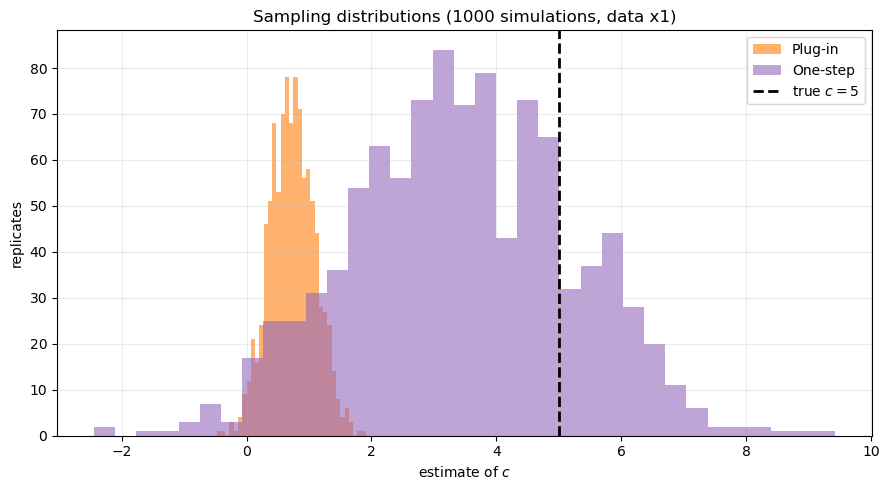

In [86]:
if run_simulation:
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(plug_in_estimates[valid_plugin], bins=35, alpha=0.6, color="C1", label="Plug-in")
    ax.hist(one_step_estimates[valid_os], bins=35, alpha=0.6, color="C4", label="One-step")
    ax.axvline(c_true, color="black", linestyle="--", linewidth=2, label=fr"true $c={c_true:g}$")
    ax.set(xlabel="estimate of $c$", ylabel="replicates", title=f"Sampling distributions ({N_sim} simulations, data x{R})")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

---
## 8. Coverage diagnostics

The following cells show the one-step CI strip plot, empirical coverage and interval widths, and the full coverage-calibration curve. If `compute_bootstrap_coverage=True`, the plug-in bootstrap interval is included as well.

In [26]:
if run_simulation:
    valid_ci = np.all(np.isfinite(CIs_one_step), axis=1)

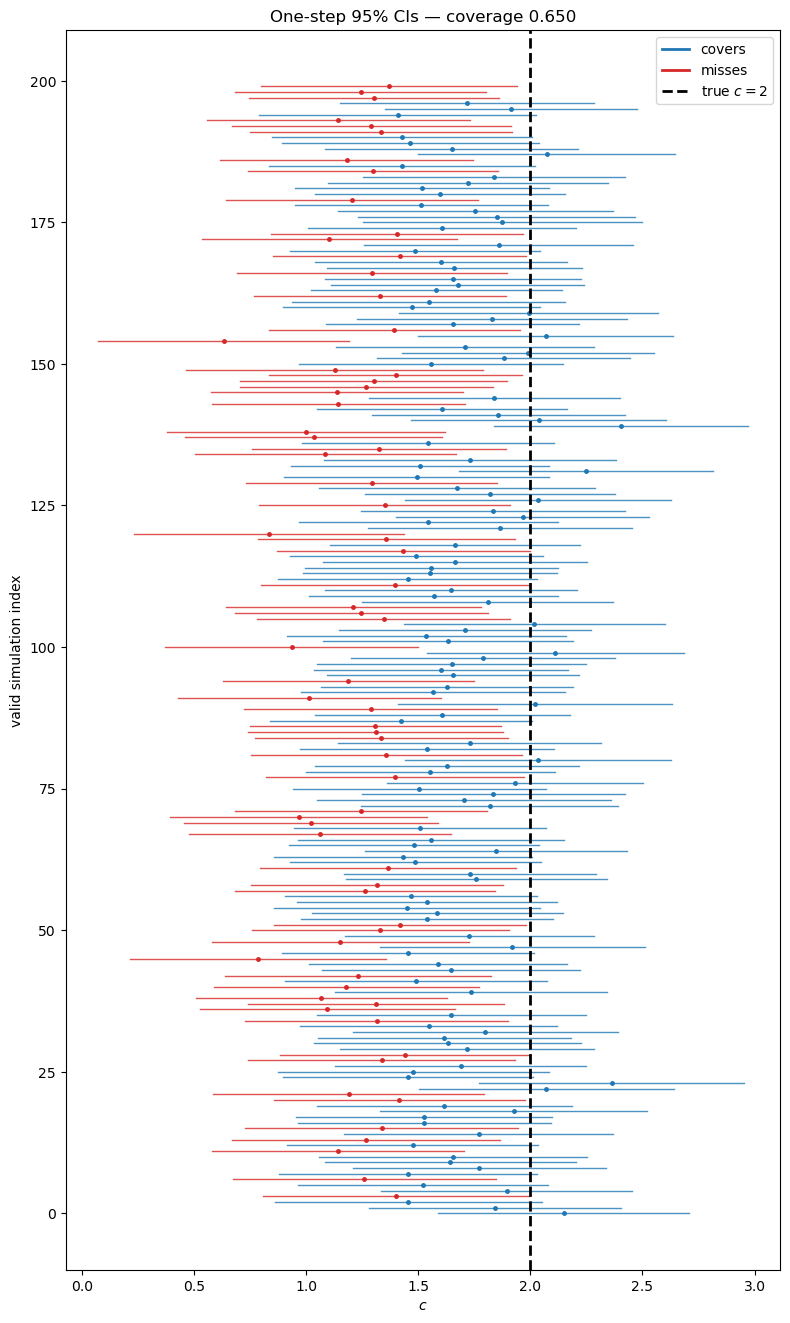

In [ ]:
if run_simulation:
    ci_indices = np.flatnonzero(valid_ci)
    coverage_colors = ["C0" if covered_one_step[i] else "C3" for i in ci_indices]

    fig, ax = plt.subplots(figsize=(8, max(5, len(ci_indices) / 15)))
    for row, (idx, color) in enumerate(zip(ci_indices, coverage_colors)):
        ax.plot(CIs_one_step[idx], [row, row], color=color, lw=1, alpha=0.8)
        ax.plot(one_step_estimates[idx], row, "o", color=color, ms=2.5)
    ax.axvline(c_true, color="black", lw=2, ls="--")
    coverage_rate = covered_one_step[valid_ci].mean()
    ax.legend(handles=[
        Line2D([0], [0], color="C0", lw=2, label="covers"),
        Line2D([0], [0], color="C3", lw=2, label="misses"),
        Line2D([0], [0], color="black", lw=2, ls="--", label=fr"true $c={c_true:g}$"),
    ])
    ax.set(xlabel="$c$", ylabel="valid simulation index", title=f"One-step 95% CIs — coverage {coverage_rate:.3f}")
    plt.tight_layout()
    plt.show()

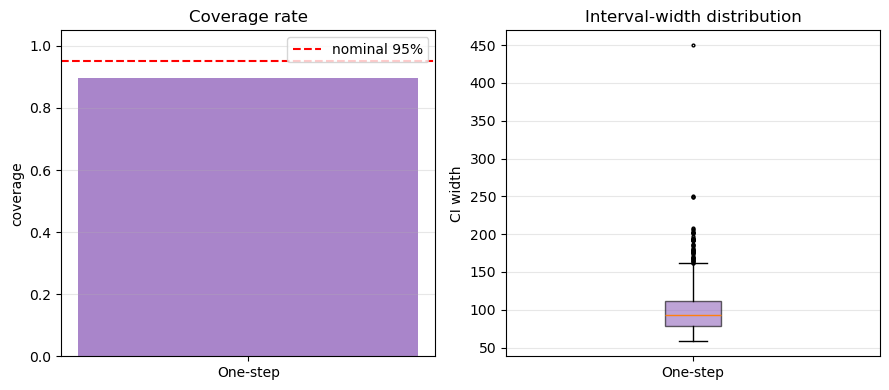

In [27]:
if run_simulation:
    labels = ["One-step"]
    CI_arrays = [CIs_one_step[valid_ci]]
    colors = ["C4"]
    if compute_bootstrap_coverage:
        valid_boot = np.all(np.isfinite(CIs_mle), axis=1)
        labels.insert(0, "Plug-in bootstrap")
        CI_arrays.insert(0, CIs_mle[valid_boot])
        colors.insert(0, "C1")

    coverages = [np.mean((ci[:, 0] <= c_true) & (ci[:, 1] >= c_true)) for ci in CI_arrays]
    widths = [ci[:, 1] - ci[:, 0] for ci in CI_arrays]
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].bar(labels, coverages, color=colors, alpha=0.8, width=0.5)
    axes[0].axhline(0.95, color="red", linestyle="--", label="nominal 95%")
    axes[0].set(ylabel="coverage", title="Coverage rate", ylim=(0, 1.05))
    axes[0].legend()
    bp = axes[1].boxplot(widths, tick_labels=labels, patch_artist=True,
                         flierprops=dict(marker='.', markersize=4))
    for box, color in zip(bp["boxes"], colors):
        box.set_facecolor(color)
        box.set_alpha(0.6)
    axes[1].set(ylabel="CI width", title="Interval-width distribution")
    for ax in axes:
        ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

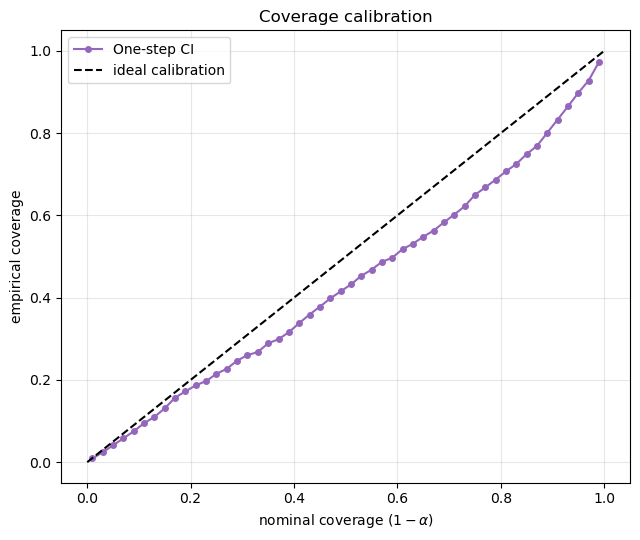

In [28]:
if run_simulation:
    alphas = np.linspace(0.01, 0.99, 50)
    nominal_levels = 1.0 - alphas
    empirical_os = []
    for alpha_i in alphas:
        z = norm.ppf(1.0 - alpha_i / 2.0)
        lo = one_step_estimates[valid_os] - z * one_step_SEs[valid_os]
        hi = one_step_estimates[valid_os] + z * one_step_SEs[valid_os]
        empirical_os.append(np.mean((lo <= c_true) & (hi >= c_true)))

    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.plot(nominal_levels, empirical_os, "o-", color="C4", ms=4, label="One-step CI")
    if compute_bootstrap_coverage:
        se_boot = np.nanstd(all_boot_samples[valid_boot], axis=1, ddof=1)
        empirical_boot = []
        plugin_valid_boot = plug_in_estimates[valid_boot]
        for alpha_i in alphas:
            z = norm.ppf(1.0 - alpha_i / 2.0)
            lo = plugin_valid_boot - z * se_boot
            hi = plugin_valid_boot + z * se_boot
            empirical_boot.append(np.mean((lo <= c_true) & (hi >= c_true)))
        ax.plot(nominal_levels, empirical_boot, "s-", color="C1", ms=4, label="Plug-in bootstrap CI")
    ax.plot([0, 1], [0, 1], "k--", label="ideal calibration")
    ax.set(xlabel=r"nominal coverage $(1-\alpha)$", ylabel="empirical coverage", title="Coverage calibration")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [27]:
save_simulation_results = False
simulation_output = "simulation_results/V3_closure_results.npz"

if run_simulation and save_simulation_results:
    from pathlib import Path
    Path(simulation_output).parent.mkdir(parents=True, exist_ok=True)
    np.savez(
        simulation_output, c_true=c_true, N_sim=N_sim,
        data_replication_factor=R,
        plug_in_estimates=plug_in_estimates, one_step_estimates=one_step_estimates,
        CIs_one_step=CIs_one_step, one_step_SEs=one_step_SEs,
        CIs_mle=CIs_mle, all_boot_samples=all_boot_samples,
        simulation_fit_method=simulation_fit_method,
        compute_bootstrap_coverage=compute_bootstrap_coverage,
    )
    print(f"Saved {simulation_output}")